## Loading the dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [2]:
# Shared appearance for new pandas and Matplotlib plots.
# Keep axis scales, bins, and whisker rules specific to each analysis.
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 120,
    "figure.autolayout": True,
    "figure.facecolor": "white",
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.size": 10,
    "text.color": "#183153",
    "axes.facecolor": "white",
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#183153",
    "axes.labelsize": 11,
    "axes.labelpad": 8,
    "axes.titlesize": 13,
    "axes.titlepad": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#94a3b8",
    "grid.alpha": 0.18,
    "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=[
        "#6baed6", "#3182bd", "#183153",
        "#e6550d", "#31a354", "#756bb1",
    ]),
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "lines.linewidth": 2,
    "patch.edgecolor": "white",
    "patch.force_edgecolor": True,
    "patch.linewidth": 0.8,
    "legend.frameon": False,
    "boxplot.patchartist": True,
    "boxplot.showmeans": True,
    "boxplot.boxprops.color": "#3182bd",
    "boxplot.whiskerprops.color": "#3182bd",
    "boxplot.capprops.color": "#3182bd",
    "boxplot.medianprops.color": "#183153",
    "boxplot.medianprops.linewidth": 2,
    "boxplot.flierprops.marker": "o",
    "boxplot.flierprops.markersize": 3,
    "boxplot.flierprops.markerfacecolor": "#3182bd40",
    "boxplot.flierprops.markeredgecolor": "none",
    "boxplot.meanprops.marker": "D",
    "boxplot.meanprops.markersize": 5,
    "boxplot.meanprops.markerfacecolor": "#e6550d",
    "boxplot.meanprops.markeredgecolor": "white",
})

In [3]:
from recsys.data import load_movielens

In [4]:
dataset = load_movielens("data/ml-1m")

## Inspect the dataset

### Users

In [5]:
users = dataset.users
users.head()

,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [6]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     6040 non-null   int64 
 1   gender      6040 non-null   string
 2   age         6040 non-null   int64 
 3   occupation  6040 non-null   int64 
 4   zip_code    6040 non-null   string
dtypes: int64(3), string(2)
memory usage: 271.8 KB


In [7]:
users["user_id"].nunique()

6040

There are 6040 users as described in the project docs. All entries are non-null and all user_ids are unique.

We can inspect the age, gender and occupation distributions

In [8]:
age_labels = {
    1: "Under 18",
    18: "18–24",
    25: "25–34",
    35: "35–44",
    45: "45–49",
    50: "50–55",
    56: "56+",
}

occupation_labels = {
    0: "Other / unspecified",
    1: "Academic / educator",
    2: "Artist",
    3: "Clerical / admin",
    4: "College / grad student",
    5: "Customer service",
    6: "Doctor / health care",
    7: "Executive / managerial",
    8: "Farmer",
    9: "Homemaker",
    10: "K–12 student",
    11: "Lawyer",
    12: "Programmer",
    13: "Retired",
    14: "Sales / marketing",
    15: "Scientist",
    16: "Self-employed",
    17: "Technician / engineer",
    18: "Tradesman / craftsman",
    19: "Unemployed",
    20: "Writer",
}

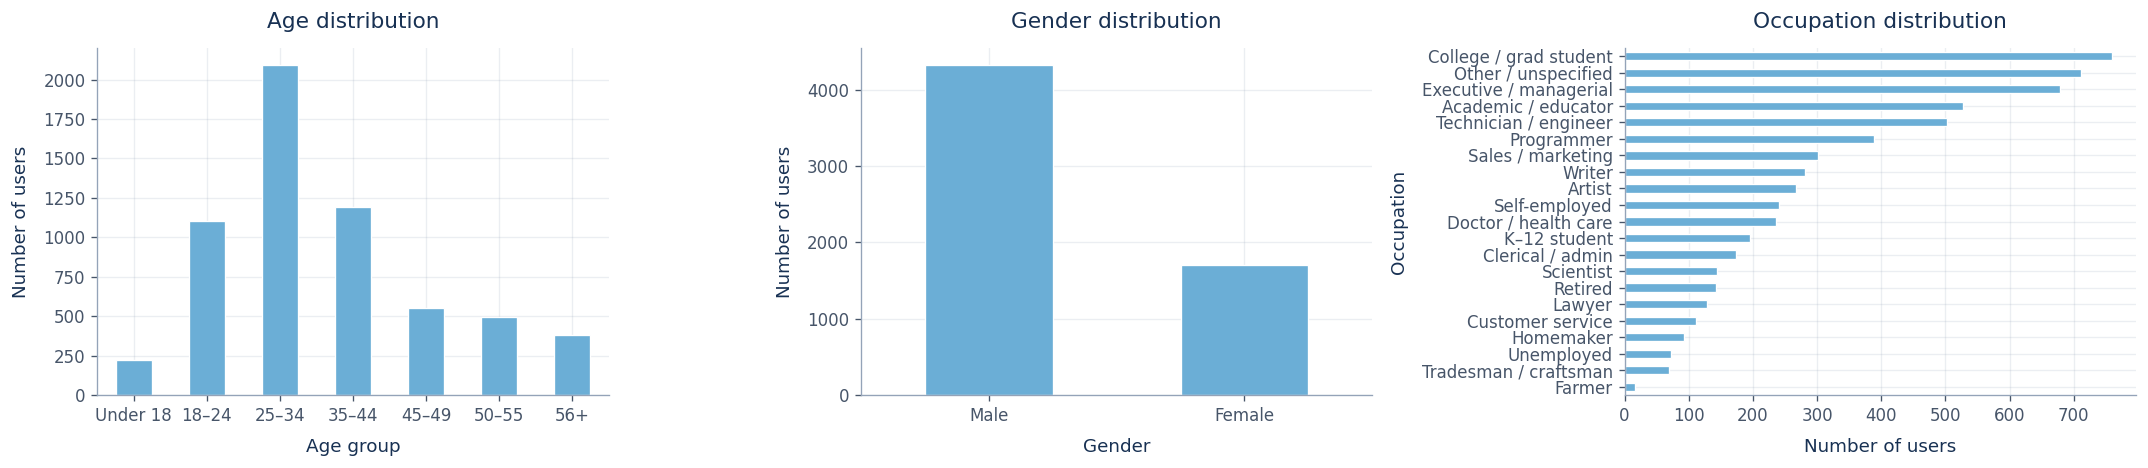

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

dataset.users["age"].value_counts().sort_index().rename(
    index=age_labels
).plot.bar(
    ax=axes[0], title="Age distribution",
    xlabel="Age group", ylabel="Number of users", rot=0,
)

dataset.users["gender"].value_counts().rename(
    index={"F": "Female", "M": "Male"}
).plot.bar(
    ax=axes[1], title="Gender distribution",
    xlabel="Gender", ylabel="Number of users", rot=0,
)

dataset.users["occupation"].value_counts().rename(
    index=occupation_labels
).sort_values().plot.barh(
    ax=axes[2], title="Occupation distribution",
    xlabel="Number of users", ylabel="Occupation",
)

plt.tight_layout()
plt.show()

### Movies

In [10]:
movies = dataset.movies
movies.head()

,item_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [11]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   item_id  3883 non-null   int64 
 1   title    3883 non-null   string
 2   genres   3883 non-null   string
dtypes: int64(1), string(2)
memory usage: 225.4 KB


In [12]:
movies["item_id"].nunique()

3883

There are 3883 unique movies.

Let's explore the release year and genre distribution 

In [13]:
release_years = (
    dataset.movies["title"]
    .str.extract(r"\((\d{4})\)$", expand=False)
    .astype("Int64")
)

genres = dataset.movies["genres"].str.split("|", regex=False).explode()

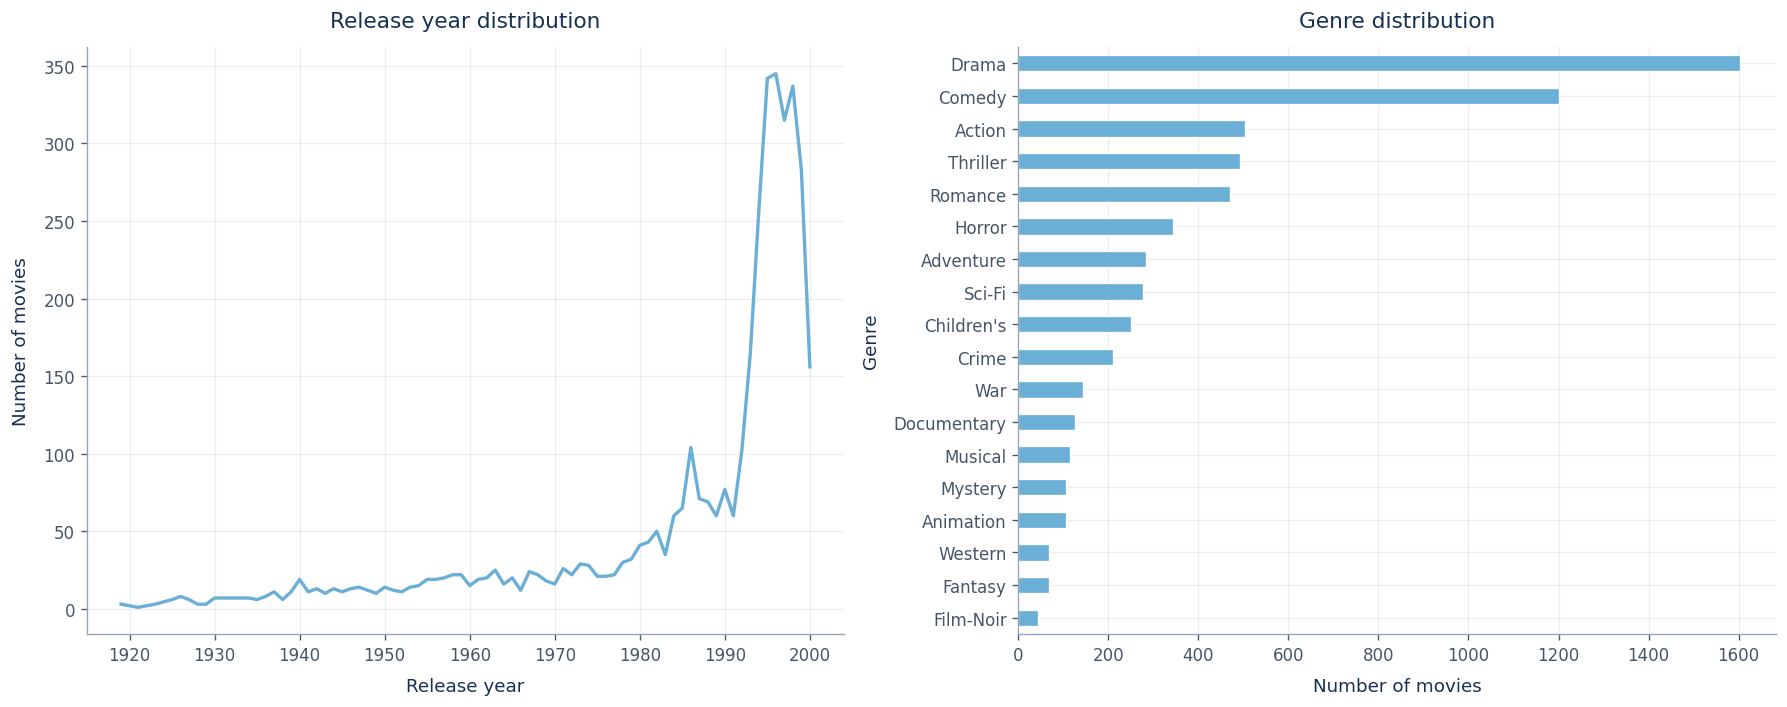

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

release_years.value_counts().sort_index().plot(
    ax=axes[0], title="Release year distribution",
    xlabel="Release year", ylabel="Number of movies",
)

genres.value_counts().sort_values().plot.barh(
    ax=axes[1], title="Genre distribution",
    xlabel="Number of movies", ylabel="Genre",
)

plt.tight_layout()
plt.show()

### Ratings

In [15]:
ratings = dataset.ratings
ratings.head()

,user_id,item_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [16]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   item_id    1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


In [17]:
timestamps = pd.to_datetime(
    dataset.ratings["timestamp"], unit="s", utc=True
)

month_bins = pd.date_range(
    start=timestamps.min().normalize().replace(day=1),
    end=timestamps.max().normalize().replace(day=1) + pd.offsets.MonthBegin(1),
    freq="MS",
)

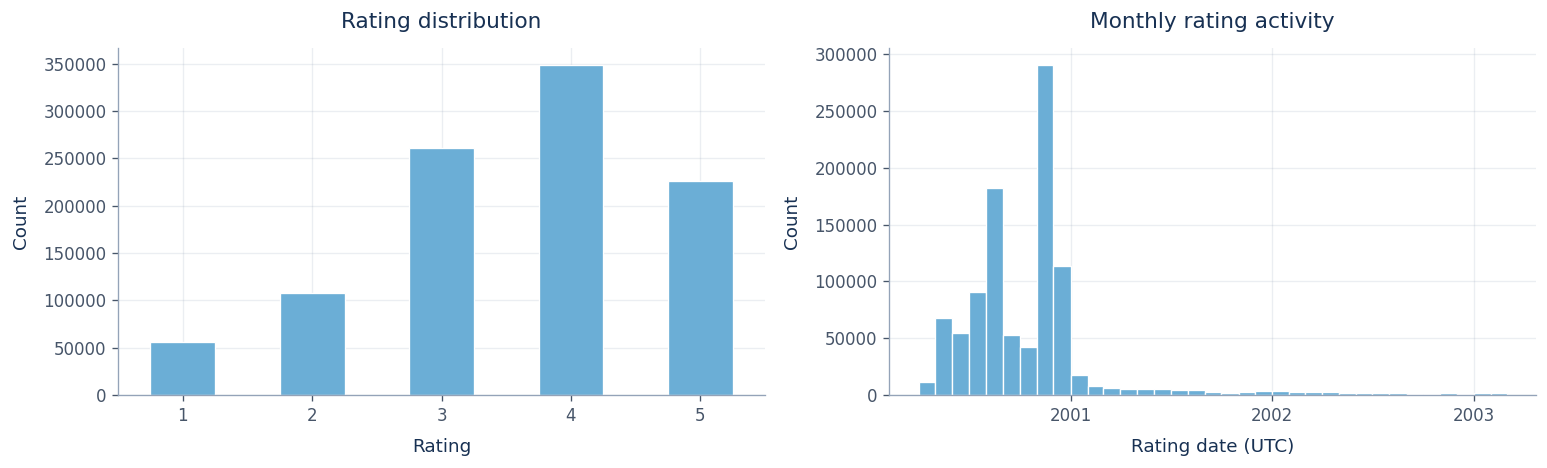

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dataset.ratings["rating"].value_counts().sort_index().plot.bar(
    ax=axes[0], title="Rating distribution",
    xlabel="Rating", ylabel="Count", rot=0,
)

timestamps.hist(
    ax=axes[1],
    bins=mdates.date2num(month_bins.to_pydatetime()),
)
axes[1].set(
    title="Monthly rating activity",
    xlabel="Rating date (UTC)", ylabel="Count",
)

locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

plt.tight_layout()
plt.show()

In terms of rating distribution, low ratings seem under represented. In the temporal distribution of the rating counts we see most of the ratings happened in the year 2000, there is a great drop for ratings in 2001 and the rating counts continue to decrease slowly with time.

### Density

The density is the ratio of the number of ratings available to the total number of possible ratings there can be.

In [19]:
density = len(ratings) / (
    ratings["user_id"].nunique() * ratings["item_id"].nunique()
)
print(f"Density: {density:.2%}")

Density: 4.47%


To get a feel of this density we can take a random sample of users and movies and plot the ratings matrix

In [20]:
sampled_users = dataset.users["user_id"].sample(n=100, random_state=42)
sampled_movies = dataset.movies["item_id"].sample(n=200, random_state=42)

sample = ratings[
    ratings["user_id"].isin(sampled_users)
    & ratings["item_id"].isin(sampled_movies)
]

# Reindex to retain sampled users/movies with no ratings in this sample.
observed = (
    pd.crosstab(sample["user_id"], sample["item_id"])
    .reindex(index=sampled_users, columns=sampled_movies, fill_value=0)
    .gt(0)
)

sample_density = observed.to_numpy().mean()

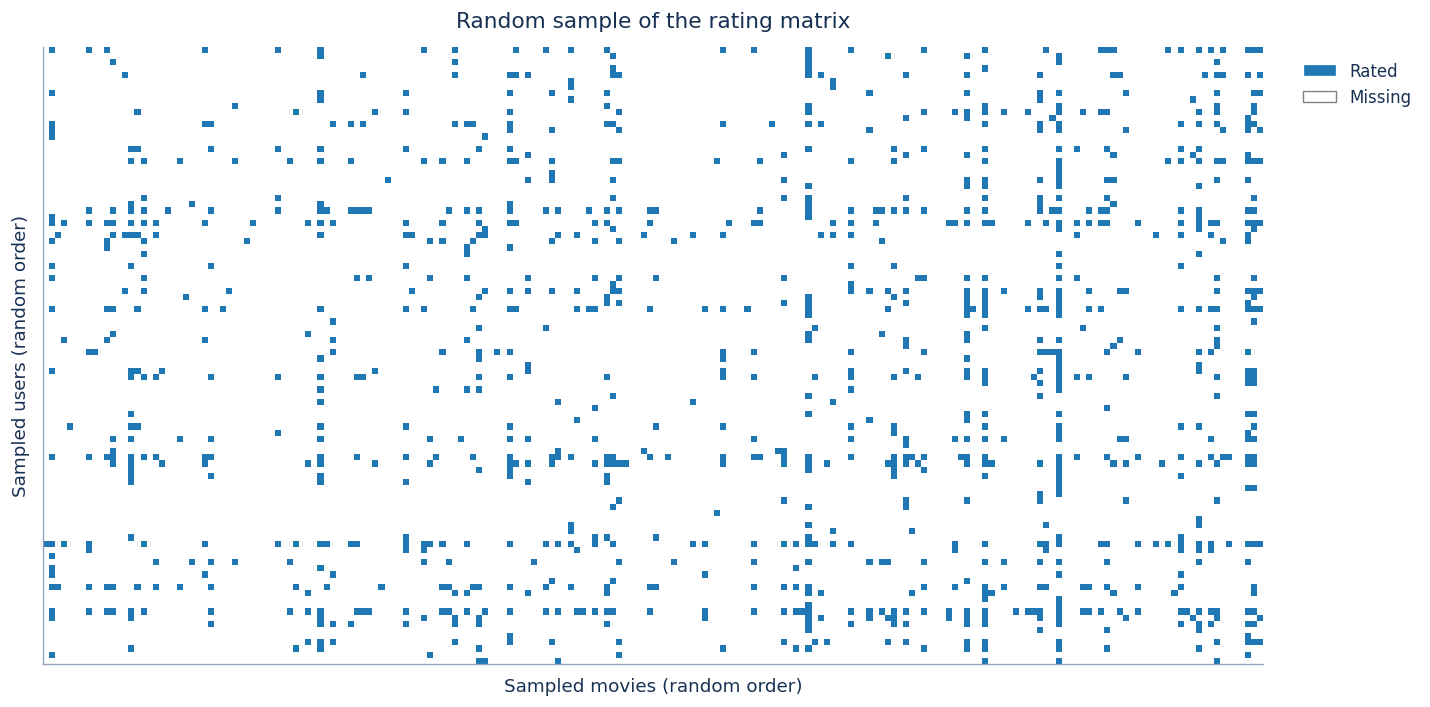

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.imshow(
    observed,
    cmap=ListedColormap(["white", "tab:blue"]),
    interpolation="nearest",
    aspect="auto",
    vmin=0, vmax=1,
)

ax.set(
    title="Random sample of the rating matrix",
    xlabel="Sampled movies (random order)",
    ylabel="Sampled users (random order)",
    xticks=[], yticks=[],
)

ax.legend(
    handles=[
        Patch(facecolor="tab:blue", label="Rated"),
        Patch(facecolor="white", edgecolor="gray", label="Missing"),
    ],
    loc="upper left", bbox_to_anchor=(1.02, 1),
)

plt.tight_layout()
plt.show()

### Distribution of interactions per user

In [22]:
interactions_per_user = ratings.groupby("user_id").size()

user_counts = interactions_per_user.value_counts().sort_index()
cumulative_share = user_counts.cumsum() / user_counts.sum()
quartiles = interactions_per_user.quantile([0.25, 0.50, 0.75])
ecdf = pd.concat([pd.Series([0.0], index=[0]), cumulative_share])

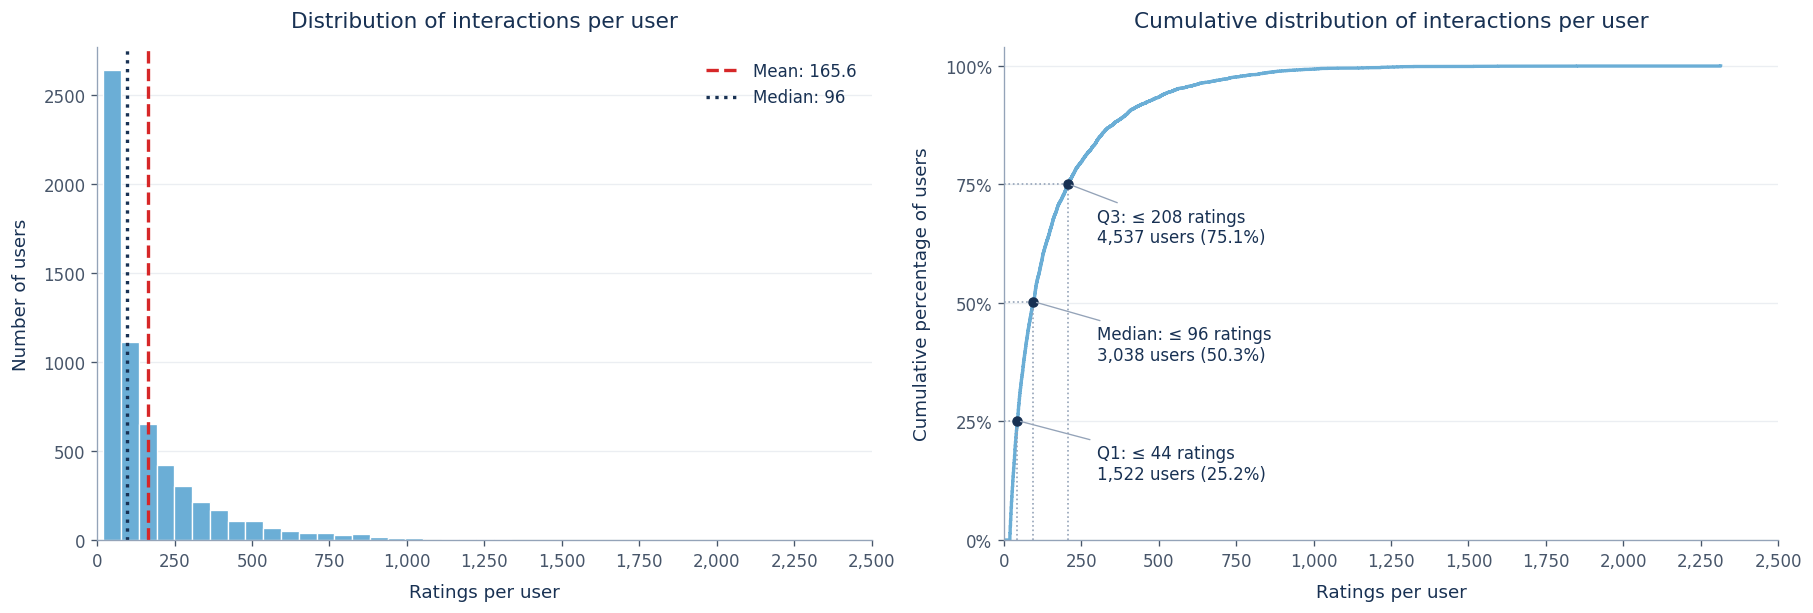

In [23]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), sharex=True, layout="constrained"
)

interactions_per_user.plot.hist(
    ax=axes[0], bins=40,
    title="Distribution of interactions per user",
    xlabel="Ratings per user", ylabel="Number of users",
)
axes[0].axvline(
    interactions_per_user.mean(), color="tab:red", linestyle="--",
    label=f"Mean: {interactions_per_user.mean():.1f}",
)
axes[0].axvline(
    interactions_per_user.median(), color="#183153", linestyle=":",
    label=f"Median: {interactions_per_user.median():g}",
)
axes[0].legend()

ecdf.plot(
    ax=axes[1], drawstyle="steps-post", linewidth=2,
    title="Cumulative distribution of interactions per user",
    xlabel="Ratings per user", ylabel="Cumulative percentage of users",
)
axes[1].set_ylim(0, 1.04)
axes[1].set_yticks(
    [0, 0.25, 0.50, 0.75, 1],
    labels=["0%", "25%", "50%", "75%", "100%"],
)

for name, cutoff in zip(["Q1", "Median", "Q3"], quartiles):
    n_users = interactions_per_user.le(cutoff).sum()
    share = n_users / len(interactions_per_user)
    axes[1].vlines(cutoff, 0, share, color="#94a3b8", linestyle=":", linewidth=1)
    axes[1].hlines(share, 0, cutoff, color="#94a3b8", linestyle=":", linewidth=1)
    axes[1].scatter([cutoff], [share], color="#183153", s=30, zorder=3)
    axes[1].annotate(
        f"{name}: ≤ {cutoff:g} ratings\n{n_users:,} users ({share:.1%})",
        xy=(cutoff, share), xytext=(300, share - 0.05),
        textcoords="data", va="top", fontsize=10,
        arrowprops=dict(arrowstyle="-", color="#94a3b8", linewidth=0.8),
    )

for ax in axes:
    ax.set_xscale("linear")
    ax.set_xlim(0, max(2500, interactions_per_user.max() * 1.05))
    ticks = range(0, 2501, 250)
    ax.set_xticks(ticks, labels=[f"{tick:,}" for tick in ticks])
    ax.grid(False)
    ax.grid(axis="y", alpha=0.18)

plt.show()


We see a very skewed distribution of ratings per user: most users rank a small portion of the total movies, with more than 75% of users rating less than 250 out of the 38883 movies, while some rank more than 1000.

### Distribution of interactions per item

In [24]:
interactions_per_item = (
    ratings.groupby("item_id").size()
    .reindex(movies["item_id"], fill_value=0)
)

item_counts = interactions_per_item.value_counts().sort_index()
cumulative_share = item_counts.cumsum() / item_counts.sum()
quartiles = interactions_per_item.quantile([0.25, 0.50, 0.75])
ecdf = pd.concat([pd.Series([0.0], index=[0]), cumulative_share])

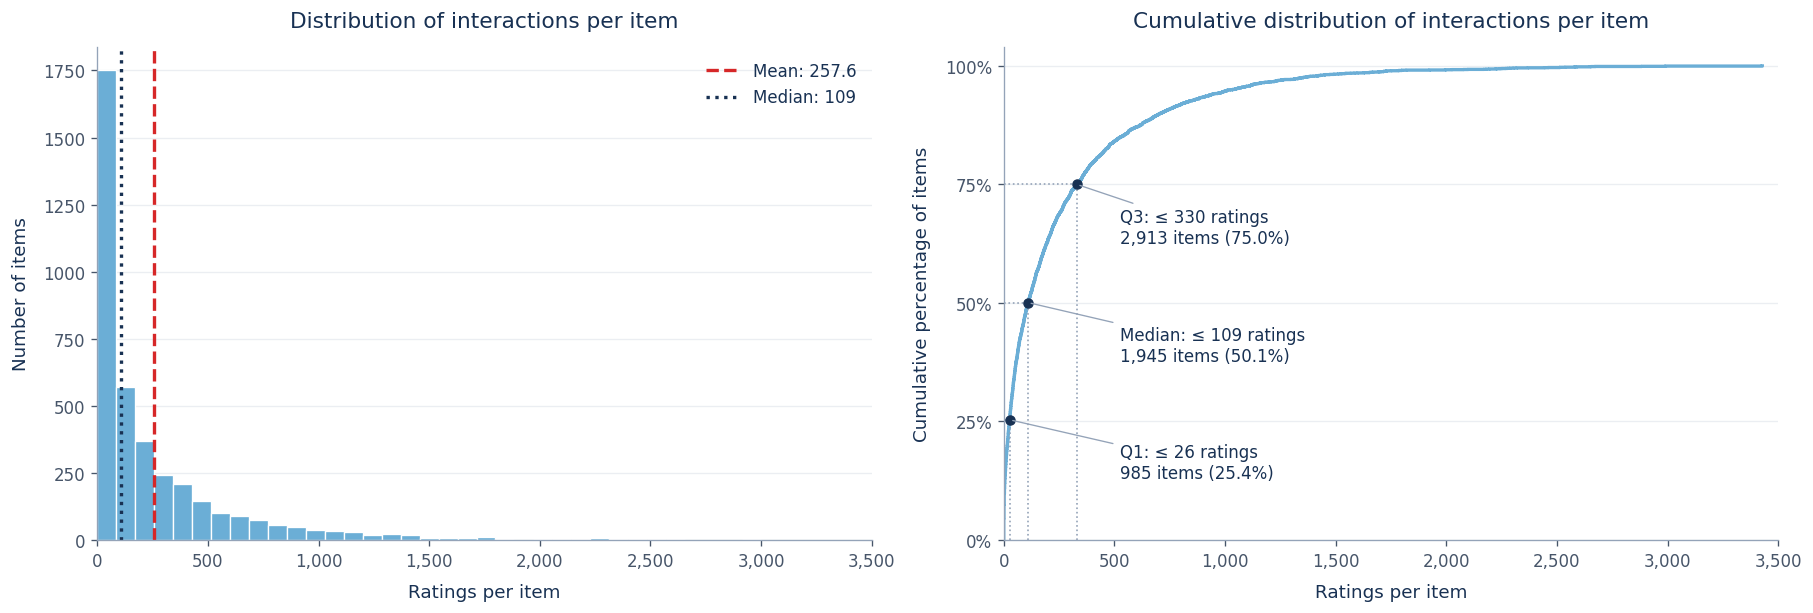

In [25]:
tick_step = 500
x_max = (
    (int(interactions_per_item.max()) + tick_step - 1) // tick_step
) * tick_step

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), sharex=True, layout="constrained"
)

interactions_per_item.plot.hist(
    ax=axes[0], bins=40,
    title="Distribution of interactions per item",
    xlabel="Ratings per item", ylabel="Number of items",
)
axes[0].axvline(
    interactions_per_item.mean(), color="tab:red", linestyle="--",
    label=f"Mean: {interactions_per_item.mean():.1f}",
)
axes[0].axvline(
    interactions_per_item.median(), color="#183153", linestyle=":",
    label=f"Median: {interactions_per_item.median():g}",
)
axes[0].legend()

ecdf.plot(
    ax=axes[1], drawstyle="steps-post", linewidth=2,
    title="Cumulative distribution of interactions per item",
    xlabel="Ratings per item", ylabel="Cumulative percentage of items",
)
axes[1].set_ylim(0, 1.04)
axes[1].set_yticks(
    [0, 0.25, 0.50, 0.75, 1],
    labels=["0%", "25%", "50%", "75%", "100%"],
)

for name, cutoff in zip(["Q1", "Median", "Q3"], quartiles):
    n_items = interactions_per_item.le(cutoff).sum()
    share = n_items / len(interactions_per_item)

    axes[1].vlines(
        cutoff, 0, share,
        color="#94a3b8", linestyle=":", linewidth=1,
    )
    axes[1].hlines(
        share, 0, cutoff,
        color="#94a3b8", linestyle=":", linewidth=1,
    )
    axes[1].scatter(
        [cutoff], [share], color="#183153", s=30, zorder=3,
    )
    axes[1].annotate(
        f"{name}: ≤ {cutoff:g} ratings\n{n_items:,} items ({share:.1%})",
        xy=(cutoff, share),
        xytext=(x_max * 0.15, share - 0.05),
        textcoords="data", va="top", fontsize=10,
        arrowprops=dict(
            arrowstyle="-", color="#94a3b8", linewidth=0.8,
        ),
    )

for ax in axes:
    ax.set_xscale("linear")
    ax.set_xlim(0, x_max)
    ticks = range(0, x_max + 1, tick_step)
    ax.set_xticks(ticks, labels=[f"{tick:,}" for tick in ticks])
    ax.grid(False)
    ax.grid(axis="y", alpha=0.18)

plt.show()

We see again a very skewed distribution: with the 75% of the items having less than 330 ratings, while a few items are ranked over 2000 times.

In [26]:
import numpy as np
from sklearn.metrics import ndcg_score  

SEED = 42  

rating_time = pd.to_datetime(ratings["timestamp"], unit="s", utc=True)

# Share of all ratings per calendar year
share_per_year = rating_time.dt.year.value_counts(normalize=True).sort_index()
print("Share of ratings per calendar year:")
print(share_per_year.map("{:.1%}".format).to_string(), end="\n\n")

# How long does a user stay active? 
user_time = ratings.groupby("user_id")["timestamp"].agg(["min", "max"])
user_span_days = (user_time["max"] - user_time["min"]) / 86400

print(f"Users whose ratings all fall within 24 hours : {(user_span_days < 1).mean():.1%}")
print(f"Users whose ratings all fall within 7 days   : {(user_span_days < 7).mean():.1%}")
print(f"Median active span per user                  : {user_span_days.median() * 24:.1f} hours")

busiest = rating_time.dt.tz_convert(None).dt.to_period("M").value_counts().idxmax()
busiest_share = (rating_time.dt.tz_convert(None).dt.to_period("M") == busiest).mean()
print(f"Busiest month: {busiest} ({busiest_share:.1%} of all ratings)")

Share of ratings per calendar year:
timestamp
2000    90.5%
2001     6.8%
2002     2.4%
2003     0.3%

Users whose ratings all fall within 24 hours : 62.9%
Users whose ratings all fall within 7 days   : 70.2%
Median active span per user                  : 1.1 hours
Busiest month: 2000-11 (29.1% of all ratings)


90.5 % were made in 2000, and 29 % came in November 2000 alone. Users also tend to rate everything in one sitting: 63 % of them enter all their ratings within 24 hours, and the typical user is active for only about one hour. So a time cut does not split a user’s history in two. It puts each user on one side or the other:

Users who finish rating before the cut never show up in validation or test.
Users who start rating after the cut have no history, so collaborative filtering can’t make recommendations for them.
Only users who come back after the cut can be used for both training and testing, and there are few of them.

So it makes not easy the choice of the split.

I compare three time cuts. Each cut uses the same dates for all users (a global cut). I chose this over a per-user “leave the last items out” split because the model never trains on ratings that happened after the ones it is tested on. This is what a real system would face. A random split is ruled out for the same reason.

What I look for, from most to least important:

Validation and test should look alike (same kind of users, same level of activity). If they don’t, the settings I tune on validation won’t work well on test.
There should be enough users to evaluate. Each one needs at least one earlier rating and at least one positive rating in the window.
Cuts should fall on round calendar dates, not inside the November–December 2000 burst.
The training set should be as large as possible.
- A: the standard 80/10/10 split by number of ratings. The cuts fall on 2000-12-02 and 2000-12-29, inside the burst.
- B: cuts at the end of the burst. Validation is December 2000 and test is 2001 onwards.
- C: validation is January–June 2001 and test is July 2001 onwards.

In [27]:
POSITIVE_THRESHOLD = 4  # rating >= 4 is a "like" 


def to_epoch(date_str):
    """UTC date string -> epoch seconds (same unit as the `timestamp` column)."""
    return int(pd.Timestamp(date_str, tz="UTC").timestamp())


def temporal_split(df, val_start, test_start):
    """Split by absolute time: train < val_start <= val < test_start <= test."""
    train = df[df["timestamp"] < val_start]
    val = df[(df["timestamp"] >= val_start) & (df["timestamp"] < test_start)]
    test = df[df["timestamp"] >= test_start]
    return train, val, test


def split_diagnostics(val_start, test_start, label):
    """Size of each part and how many users can actually be evaluated.

    A user is evaluable in a window if they have at least one earlier interaction
    (otherwise a CF model knows nothing about them) and at least one positive
    rating inside the window (otherwise there is nothing to retrieve).
    """
    train, val, test = temporal_split(ratings, val_start, test_start)
    row = {
        "split": label,
        "train rows": len(train),
        "val rows": len(val),
        "test rows": len(test),
    }
    for name, window, history in (
        ("val", val, train),
        ("test", test, pd.concat([train, val])),
    ):
        known_users = history["user_id"].unique()
        positives = window[window["rating"] >= POSITIVE_THRESHOLD]
        evaluable = np.intersect1d(positives["user_id"].unique(), known_users)
        row[f"{name} evaluable users"] = len(evaluable)
        row[f"{name} rows from users without history (%)"] = (
            100 * (~window["user_id"].isin(known_users)).mean()
        )
    return row


candidate_splits = [
    # A: the textbook 80/10/10 split by number of ratings (cuts at time quantiles)
    ("A: 80/10/10 by rating count",
     int(ratings["timestamp"].quantile(0.80)), int(ratings["timestamp"].quantile(0.90))),
    # B: calendar cuts right after the Nov-Dec 2000 burst: val = Dec 2000, test = 2001 onwards
    ("B: val = Dec 2000, test = 2001+",
     to_epoch("2000-12-01"), to_epoch("2001-01-01")),
    # C: calendar cuts after the burst: val = Jan-Jun 2001, test = Jul 2001 onwards
    ("C: val = H1 2001, test = Jul 2001+",
     to_epoch("2001-01-01"), to_epoch("2001-07-01")),
]

diagnostics = pd.DataFrame(
    [split_diagnostics(v, t, label) for label, v, t in candidate_splits]
).set_index("split")

for name, v, t in candidate_splits:
    print(f"{name:38s} val starts {pd.to_datetime(v, unit='s', utc=True):%Y-%m-%d}, "
          f"test starts {pd.to_datetime(t, unit='s', utc=True):%Y-%m-%d}")

diagnostics.T.round(1)

A: 80/10/10 by rating count            val starts 2000-12-02, test starts 2000-12-29
B: val = Dec 2000, test = 2001+        val starts 2000-12-01, test starts 2001-01-01
C: val = H1 2001, test = Jul 2001+     val starts 2001-01-01, test starts 2001-07-01


split,A: 80/10/10 by rating count,"B: val = Dec 2000, test = 2001+","C: val = H1 2001, test = Jul 2001+"
train rows,800164.0,791270.0,904757.0
val rows,100024.0,113487.0,47314.0
test rows,100021.0,95452.0,48138.0
val evaluable users,492.0,538.0,892.0
val rows from users without history (%),76.2,75.0,0.4
test evaluable users,1159.0,1150.0,777.0
test rows from users without history (%),4.2,1.1,1.1


I use split C. Train covers 2000-04-25 to 2000-12-31 (904,757 ratings, 90.5 %). Validation covers January to June 2001 (47,314 ratings, 4.7 %). Test covers July 2001 to February 2003 (48,138 ratings, 4.8 %).

For A and B, the validation window falls inside or right after the burst. In that window, 75–76 % of the ratings come from users who have no earlier ratings, so we can’t test on them. Only 492 users (A) and 538 users (B) are left. Most of them are new sign-ups, while the test set is made of users who come back later. A model tuned on this validation set would be tuned for users who barely appear in test.

For C, validation and test are both after the burst. They are almost the same size (47k and 48k ratings) and contain the same kind of users: people who come back. Only 0.4 % of validation ratings and 1.1 % of test ratings come from users with no history. This gives us 892 users to test on in validation and 777 in test, which is enough for tuning and for confidence intervals. I cut on 1 January and 1 July because they are simple dates in a quiet period.

What it costs:

Train is 90.5 % of the data, and validation and test are only about 5 % each. This is because the dataset itself is 90 % burst.
We only test on users who come back, and they are more active than average. Their median is 169 ratings in validation and 212 in test, against 96 for all users. So the results say nothing about new users.
The test period lasts 20 months, so a user’s history and their test ratings can be up to two years apart.

In [28]:
VAL_START = to_epoch("2001-01-01")
TEST_START = to_epoch("2001-07-01")

train_df, val_df, test_df = temporal_split(ratings, VAL_START, TEST_START)

# Fixed catalogue and user index, built once from the full data so that every
# model ranks the same ~3.7k items (items that never receive a rating can never
# be a test positive, so the 177 unrated entries of movies.dat are left out).
user_ids = np.sort(ratings["user_id"].unique())
catalogue = np.sort(ratings["item_id"].unique())
n_users, n_items = len(user_ids), len(catalogue)
user_index = {u: k for k, u in enumerate(user_ids)}
item_index = {i: k for k, i in enumerate(catalogue)}
print(f"{n_users} users, {n_items} catalogue items "
      f"(movies.dat lists {len(movies)}, {len(movies) - n_items} are never rated)")

split_summary = pd.DataFrame(
    {
        name: {
            "rows": len(part),
            "share of rows": f"{len(part) / len(ratings):.1%}",
            "first rating (UTC)": f"{pd.to_datetime(part['timestamp'].min(), unit='s', utc=True):%Y-%m-%d}",
            "last rating (UTC)": f"{pd.to_datetime(part['timestamp'].max(), unit='s', utc=True):%Y-%m-%d}",
            "distinct users": part["user_id"].nunique(),
            "distinct items": part["item_id"].nunique(),
        }
        for name, part in (("train", train_df), ("validation", val_df), ("test", test_df))
    }
)
split_summary

6040 users, 3706 catalogue items (movies.dat lists 3883, 177 are never rated)


,train,validation,test
rows,904757,47314,48138
share of rows,90.5%,4.7%,4.8%
first rating (UTC),2000-04-25,2001-01-01,2001-07-01
last rating (UTC),2000-12-31,2001-06-30,2003-02-28
distinct users,6034,926,799
distinct items,3678,3157,3237


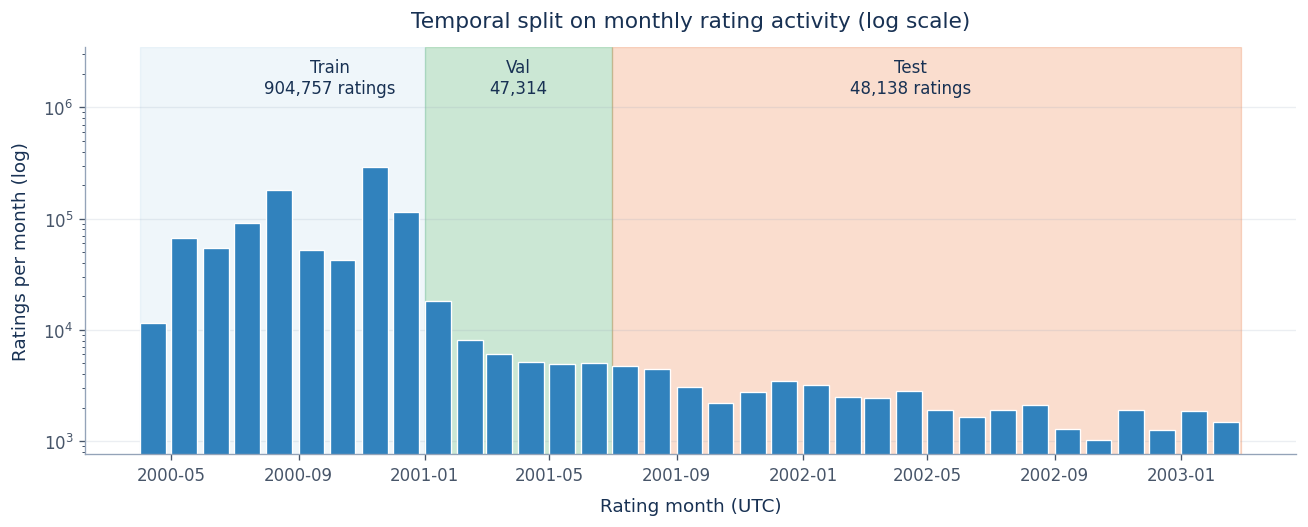

In [29]:
monthly = (
    rating_time.dt.tz_convert(None).dt.to_period("M").value_counts().sort_index()
)
month_start = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(month_start, monthly.values, width=25, align="edge", color="#3182bd")
ax.set_yscale("log")
ax.set_ylim(top=monthly.max() * 12)  # headroom for the labels

val_start_dt = pd.to_datetime(VAL_START, unit="s", utc=True).tz_convert(None)
test_start_dt = pd.to_datetime(TEST_START, unit="s", utc=True).tz_convert(None)
ax.axvspan(month_start.min(), val_start_dt, color="#6baed6", alpha=0.10, zorder=0)
ax.axvspan(val_start_dt, test_start_dt, color="#31a354", alpha=0.25, zorder=0)
ax.axvspan(test_start_dt, month_start.max() + pd.offsets.MonthEnd(1),
           color="#e6550d", alpha=0.20, zorder=0)

ymax = ax.get_ylim()[1]
ax.text(pd.Timestamp("2000-10-01"), ymax * 0.8, f"Train\n{len(train_df):,} ratings", ha="center", va="top")
ax.text(pd.Timestamp("2001-04-01"), ymax * 0.8, f"Val\n{len(val_df):,}", ha="center", va="top")
ax.text(pd.Timestamp("2002-04-15"), ymax * 0.8, f"Test\n{len(test_df):,} ratings", ha="center", va="top")

ax.set(
    title="Temporal split on monthly rating activity (log scale)",
    xlabel="Rating month (UTC)", ylabel="Ratings per month (log)",
)
plt.show()

### Filtering

ML-1M already guarantees at least 20 ratings per user. The table below shows what a filter on the training data would remove, for a range of thresholds (the 28 items and 6 users at threshold 1 are those with no training rating at all).

In [30]:
# What the dataset already guarantees for users
print(f"Fewest ratings by any user in the full data: {ratings.groupby('user_id').size().min()}")

#  What a filter on the training data would remove
item_train_count = (
    train_df.groupby("item_id").size().reindex(catalogue, fill_value=0)
)
user_train_count = (
    train_df.groupby("user_id").size().reindex(user_ids, fill_value=0)
)

rows = []
for threshold in (1, 5, 10, 20, 50):
    low_items = item_train_count.index[item_train_count < threshold]
    low_users = user_train_count.index[user_train_count < threshold]
    rows.append({
        "min training ratings": threshold,
        "items dropped": len(low_items),
        "items dropped (%)": 100 * len(low_items) / n_items,
        "rows removed by item filter": int(train_df["item_id"].isin(low_items).sum()),
        "rows removed (%)": 100 * train_df["item_id"].isin(low_items).mean(),
        "users dropped": len(low_users),
        "rows removed by user filter": int(train_df["user_id"].isin(low_users).sum()),
    })

pd.DataFrame(rows).set_index("min training ratings").round(2)

Fewest ratings by any user in the full data: 20


,items dropped,items dropped (%),rows removed by item filter,rows removed (%),users dropped,rows removed by user filter
min training ratings,,,,,,
1,28,0.76,0,0.00,6,0
5,333,8.99,612,0.07,10,12
10,503,13.57,1784,0.20,63,364
20,755,20.37,5404,0.60,102,902
50,1293,34.89,23501,2.60,1894,59287


Decision: no filtering. I remove no users and no items, so 0 rows are removed.

Users: The dataset already guarantees at least 20 ratings per user. Six users have no ratings in the training set, because they only start rating after the cut. I keep them in the data. They are just new users with no history.
Items: Even a minimum of 5 ratings would remove 333 movies (9 % of the catalogue), but only 612 ratings (0.07 %). A minimum of 50 would remove 35 % of the movies, but only 2.6 % of the ratings. The movies we would remove are the rarely rated ones (the long tail). Removing them would also shrink the catalogue, which changes how coverage is computed and makes models harder to compare.

Feedback, candidate movies and test users

- What counts as a good recommendation. A movie in the test period is “relevant” if the user rated it 4 or 5. About 58 % of all ratings are 4 or 5, so we keep most of the data and leave out lukewarm ratings (3 is the second most common rating).
- What the model learns from. For each user, the kNN only looks at which movies they rated (rated or not rated). I test two options on validation: use only the movies rated 4 or 5, or use all rated movies. The better one wins.
- Which movies the model can recommend. Every model ranks the full catalogue of 3,706 movies, except the movies the user has already rated. Recommending a movie they already saw is useless. Movies with no ratings in the training set stay in the catalogue, but the model can’t rank them well. This is rare: only 0.03 % of the liked movies in validation are in this case.
- Which users we test on. We test a user only if they have at least one earlier rating and at least one 4 or 5 rating in the test period. The others are left out, and the code counts them. Each metric is the average over the tested users, so every user counts the same.

In [31]:
def interaction_matrix(df, positives_only):
    """Dense binary (users x catalogue) matrix; positives_only keeps rating >= 4."""
    d = df[df["rating"] >= POSITIVE_THRESHOLD] if positives_only else df
    M = np.zeros((n_users, n_items), dtype=np.float32)
    M[d["user_id"].map(user_index).to_numpy(), d["item_id"].map(item_index).to_numpy()] = 1.0
    return M


def rating_matrix(df):
    """Dense explicit rating matrix (0 = not rated)."""
    M = np.zeros((n_users, n_items), dtype=np.float32)
    M[df["user_id"].map(user_index).to_numpy(), df["item_id"].map(item_index).to_numpy()] = df["rating"].to_numpy()
    return M


def evaluation_users(history_df, window_df):
    """Row indices of users with >= 1 history interaction and >= 1 positive in the window."""
    has_history = np.zeros(n_users, dtype=bool)
    has_history[history_df["user_id"].map(user_index).to_numpy()] = True
    pos = window_df[window_df["rating"] >= POSITIVE_THRESHOLD]
    has_positive = np.zeros(n_users, dtype=bool)
    has_positive[pos["user_id"].map(user_index).to_numpy()] = True

    active = np.zeros(n_users, dtype=bool)
    active[window_df["user_id"].map(user_index).to_numpy()] = True
    print(f"Users active in window: {active.sum()} | without history (excluded): "
          f"{(active & ~has_history).sum()} | with history but no positive (excluded): "
          f"{(active & has_history & ~has_positive).sum()} | evaluated: "
          f"{(has_history & has_positive).sum()}")
    return np.flatnonzero(has_history & has_positive)


# ---- Validation setup: history = train, relevant = positives in the validation window
val_users = evaluation_users(train_df, val_df)
rel_val = interaction_matrix(val_df, positives_only=True)[val_users]
seen_val = interaction_matrix(train_df, positives_only=False)[val_users]

# Cold items: validation positives on items never seen in training
train_items = set(train_df["item_id"])
cold_share = (~val_df.loc[val_df["rating"] >= POSITIVE_THRESHOLD, "item_id"].isin(train_items)).mean()
print(f"Validation positives on items absent from train: {cold_share:.2%}")

Users active in window: 926 | without history (excluded): 3 | with history but no positive (excluded): 31 | evaluated: 892
Validation positives on items absent from train: 0.03%


### Metrics

- Precision@10: the share of the 10 recommended movies that the user liked.
- Recall@10: the share of the movies the user liked that appear in the top 10.
- NDCG@10: a score that gives more credit when liked movies appear higher in the list.
- Catalogue coverage: the share of the 3,706 movies that appear in at least one user’s top 10.

In [32]:
K = 10


def top_k_items(scores, seen, k=K):
    """Top-k catalogue indices per user, already-rated items excluded.

    Ties are broken by item index (stable sort) so results are deterministic.
    """
    masked = np.where(seen > 0, -np.inf, scores)
    return np.argsort(-masked, axis=1, kind="stable")[:, :k]


def ranking_metrics(top_items, relevant, k=K):
    """Per-user Precision@k, Recall@k and NDCG@k with binary relevance."""
    hits = np.take_along_axis(relevant, top_items, axis=1)
    n_relevant = relevant.sum(axis=1)
    discount = 1.0 / np.log2(np.arange(2, k + 2))
    dcg = (hits * discount).sum(axis=1)
    ideal_dcg = np.cumsum(discount)[np.minimum(n_relevant, k).astype(int) - 1]
    return {
        "precision": hits.sum(axis=1) / k,
        "recall": hits.sum(axis=1) / n_relevant,
        "ndcg": dcg / ideal_dcg,
    }


def catalogue_coverage(top_items):
    """Fraction of the full catalogue appearing in at least one top-k list."""
    return np.unique(top_items).size / n_items



rng = np.random.default_rng(SEED)
n_check = 200
fake_scores = rng.random((n_check, n_items))
fake_top = top_k_items(fake_scores, np.zeros((n_check, n_items)))
mine = ranking_metrics(fake_top, rel_val[:n_check])

ref_ndcg = ndcg_score(rel_val[:n_check], fake_scores, k=K)  
ref_precision, ref_recall = [], []
for row in range(n_check):
    relevant_items = set(np.flatnonzero(rel_val[row]))
    hit_count = len(relevant_items & set(fake_top[row]))
    ref_precision.append(hit_count / K)
    ref_recall.append(hit_count / len(relevant_items))

assert np.isclose(mine["ndcg"].mean(), ref_ndcg)
assert np.allclose(mine["precision"], ref_precision)
assert np.allclose(mine["recall"], ref_recall)
print(f"NDCG@10 ours = {mine['ndcg'].mean():.6f} vs scikit-learn = {ref_ndcg:.6f} -> metrics verified")

NDCG@10 ours = 0.009958 vs scikit-learn = 0.009958 -> metrics verified


### Item-based kNN

For every item *i* the neighbourhood N_k(i) holds its k most similar items. The score of item *i* for user *u* is the sum of sim(i, j) over the items *j* in the user's profile that belong to N_k(i). Items already rated are removed and the 10 best are recommended (Lecture 1.2, slides 5–10).

**Tuned on validation (60 configurations):**
- similarity: binary **cosine**, **Jaccard**, and **adjusted cosine**;
- profile feedback: **positives** (rating ≥ 4) vs **all ratings**;
- neighbourhood size k ∈ {5, 10, 20, 50, 100, 200, 300, 500, 1000, 2000}.

The configuration with the best validation NDCG@10 is kept.

In [33]:
EPS = 1e-12


def similarity_matrix(kind, X_binary, R_explicit):
    """Item-item similarity (items x items), zero diagonal, negatives clipped to 0."""
    if kind in ("cosine", "jaccard"):
        co = X_binary.T @ X_binary                    # co-occurrence counts
        n = np.diag(co).copy()                        # item popularity in the profile matrix
        if kind == "cosine":
            S = co / np.sqrt(np.outer(n, n) + EPS)    # binary cosine
        else:
            S = co / (n[:, None] + n[None, :] - co + EPS)
    elif kind == "adjusted_cosine":
        # Sarwar et al. 2001: centre every rating by the user's mean rating, then cosine.
        # Always uses the explicit ratings (every rating the user gave, not only likes).
        observed = R_explicit > 0
        user_mean = R_explicit.sum(axis=1) / np.maximum(observed.sum(axis=1), 1)
        R_centred = np.where(observed, R_explicit - user_mean[:, None], 0.0).astype(np.float32)
        co = R_centred.T @ R_centred
        norm = np.sqrt(np.diag(co))
        S = co / (np.outer(norm, norm) + EPS)
    else:
        raise ValueError(kind)
    S = np.maximum(S, 0).astype(np.float32)
    np.fill_diagonal(S, 0.0)
    return S


def keep_top_k(S, k):
    """Row i keeps only the k most similar items to item i (its neighbourhood N_k(i))."""
    if k >= S.shape[0] - 1:
        return S
    neighbours = np.argpartition(-S, k, axis=1)[:, :k]
    rows = np.arange(S.shape[0])[:, None]
    S_k = np.zeros_like(S)
    S_k[rows, neighbours] = S[rows, neighbours]
    return S_k


def item_knn_scores(X_profile_users, S_k):
    """score(u, i) = sum over items j rated positively by u of sim(i, j), restricted to j in N_k(i)."""
    return X_profile_users @ S_k.T

In [34]:
SIMILARITIES = ["cosine", "jaccard", "adjusted_cosine"]
FEEDBACKS = ["positives", "all_ratings"]     # which training interactions form the user profile
K_GRID = [5, 10, 20, 50, 100, 200, 300, 500, 1000, 2000]

R_train = rating_matrix(train_df)
grid_rows, val_ndcg_per_user = [], {}

for kind in SIMILARITIES:
    for feedback in FEEDBACKS:
        X_profile = interaction_matrix(train_df, positives_only=(feedback == "positives"))
        S = similarity_matrix(kind, X_profile, R_train)
        for k in K_GRID:
            scores = item_knn_scores(X_profile[val_users], keep_top_k(S, k))
            top = top_k_items(scores, seen_val)
            m = ranking_metrics(top, rel_val)
            val_ndcg_per_user[(kind, feedback, k)] = m["ndcg"]
            grid_rows.append({
                "similarity": kind, "feedback": feedback, "k": k,
                "precision@10": m["precision"].mean(),
                "recall@10": m["recall"].mean(),
                "ndcg@10": m["ndcg"].mean(),
                "coverage": catalogue_coverage(top),
            })

grid = pd.DataFrame(grid_rows)
best = grid.loc[grid["ndcg@10"].idxmax()]
print(f"Best on validation (NDCG@10): {best['similarity']}, feedback={best['feedback']}, k={int(best['k'])}")
grid.sort_values("ndcg@10", ascending=False).head(10).round(4).reset_index(drop=True)

Best on validation (NDCG@10): cosine, feedback=positives, k=500


,similarity,feedback,k,precision@10,recall@10,ndcg@10,coverage
0,cosine,positives,500,0.1539,0.0683,0.1735,0.1058
1,cosine,positives,1000,0.1478,0.0653,0.1691,0.0818
2,cosine,positives,300,0.1488,0.0661,0.1690,0.1236
3,cosine,positives,200,0.1489,0.0690,0.1678,0.1382
4,cosine,positives,2000,0.1455,0.0625,0.1672,0.0685
5,jaccard,positives,200,0.1465,0.0657,0.1659,0.1077
6,jaccard,positives,300,0.1467,0.0648,0.1657,0.1006
7,jaccard,positives,500,0.1465,0.0654,0.1657,0.0928
8,adjusted_cosine,positives,50,0.1451,0.0699,0.1641,0.1193
9,jaccard,positives,100,0.1428,0.0697,0.1641,0.1185


In [35]:
grid.pivot_table(index=["similarity", "feedback"], columns="k", values="ndcg@10").round(4)

k                              5       10      20      50      100     200   \
similarity      feedback                                                      
adjusted_cosine all_ratings  0.1225  0.1333  0.1435  0.1514  0.1507  0.1505   
                positives    0.1432  0.1539  0.1574  0.1641  0.1633  0.1618   
cosine          all_ratings  0.0985  0.0999  0.1054  0.1136  0.1220  0.1272   
                positives    0.1337  0.1401  0.1483  0.1575  0.1629  0.1678   
jaccard         all_ratings  0.1039  0.1129  0.1138  0.1209  0.1242  0.1266   
                positives    0.1393  0.1488  0.1558  0.1588  0.1641  0.1659   

k                              300     500     1000    2000  
similarity      feedback                                     
adjusted_cosine all_ratings  0.1493  0.1454  0.1418  0.1392  
                positives    0.1607  0.1572  0.1544  0.1538  
cosine          all_ratings  0.1343  0.1377  0.1397  0.1371  
                positives    0.1690  0.1735  0.1691  0.1672  
jaccard         all_ratings  0.1294  0.1288  0.1181  0.1131  
                positives    0.1657  0.1657  0.1625  0.1611

In [36]:
# Catalogue coverage of the same configurations (share of the 3,706 items recommended to anyone)
grid.pivot_table(index=["similarity", "feedback"], columns="k", values="coverage").round(3)

k                             5      10     20     50     100    200    300   \
similarity      feedback                                                       
adjusted_cosine all_ratings  0.190  0.168  0.151  0.132  0.117  0.110  0.101   
                positives    0.174  0.157  0.139  0.119  0.105  0.097  0.089   
cosine          all_ratings  0.225  0.219  0.212  0.203  0.195  0.184  0.176   
                positives    0.203  0.186  0.176  0.170  0.157  0.138  0.124   
jaccard         all_ratings  0.195  0.178  0.165  0.154  0.149  0.142  0.134   
                positives    0.177  0.153  0.137  0.122  0.118  0.108  0.101   

k                             500    1000   2000  
similarity      feedback                          
adjusted_cosine all_ratings  0.095  0.089  0.088  
                positives    0.087  0.082  0.083  
cosine          all_ratings  0.151  0.116  0.083  
                positives    0.106  0.082  0.069  
jaccard         all_ratings  0.124  0.105  0.096  
                positives    0.093  0.084  0.080

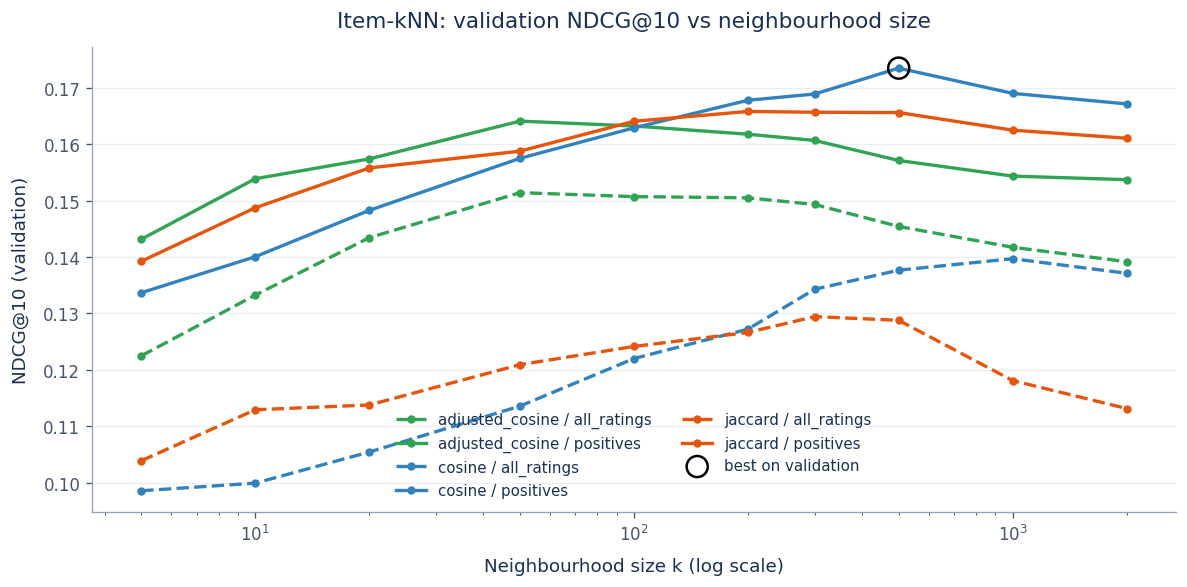

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))
colours = dict(zip(SIMILARITIES, ["#3182bd", "#e6550d", "#31a354"]))
styles = {"positives": "-", "all_ratings": "--"}

for (kind, feedback), part in grid.groupby(["similarity", "feedback"]):
    ax.plot(part["k"], part["ndcg@10"], styles[feedback], color=colours[kind],
            marker="o", markersize=4, label=f"{kind} / {feedback}")

ax.scatter([best["k"]], [best["ndcg@10"]], s=160, facecolors="none",
           edgecolors="black", linewidths=1.5, zorder=5, label="best on validation")
ax.set_xscale("log")
ax.set(title="Item-kNN: validation NDCG@10 vs neighbourhood size",
       xlabel="Neighbourhood size k (log scale)", ylabel="NDCG@10 (validation)")
ax.legend(ncol=2, fontsize=9)
plt.show()

What the grid shows.

The type of ratings we use matters most. It is better to build a user’s profile from only the movies they rated 4 or 5. This beats using all their ratings for every similarity and every k. For cosine, the best NDCG@10 is 0.174 with liked movies only, against 0.140 with all ratings. A rating of 1, 2 or 3 does not show that the user liked the movie. Using it adds recommendations that look like movies the user did not enjoy.
The similarity measure matters less. Each at its best k, cosine (0.174) is a bit better than Jaccard (0.166) and adjusted cosine (0.164). These two are about the same.
The best k depends on the similarity. Cosine and Jaccard keep improving until a few hundred neighbours. Adjusted cosine is best at k = 50. For cosine, the curve is flat between k = 200 and k = 1000 (0.168 to 0.174). So k = 500 is the top of a flat zone, not a clear best value. 500 neighbours is 13 % of the catalogue, so this model may work a bit like a “popular movies that often go together” model.
Coverage mostly goes down when k goes up. For cosine with liked movies, it goes from 20 % at k = 5 to 7 % at k = 2000. With many neighbours, the lists focus on a small group of popular movies. I don’t use coverage to choose the model, but I report it.

In [43]:
best_kind = best["similarity"]
best_feedback = best["feedback"]
best_k = int(best["k"])

history_df = pd.concat([train_df, val_df])

test_users = evaluation_users(history_df, test_df)
rel_test = interaction_matrix(test_df, positives_only=True)[test_users]
seen_test = interaction_matrix(history_df, positives_only=False)[test_users]

X_final = interaction_matrix(history_df, positives_only=(best_feedback == "positives"))
S_final = similarity_matrix(best_kind, X_final, rating_matrix(history_df))
scores = item_knn_scores(X_final[test_users], keep_top_k(S_final, best_k))
top_test = top_k_items(scores, seen_test)
m_test = ranking_metrics(top_test, rel_test)

rows = [{"metric": f"{name}@10", "value": values.mean()} for name, values in m_test.items()]
rows.append({"metric": "catalogue coverage", "value": catalogue_coverage(top_test)})

itemknn_test_results = pd.DataFrame(rows).set_index("metric")
print(f"Item-kNN ({best_kind}, feedback={best_feedback}, k={best_k}) on test, {len(test_users)} users")
itemknn_test_results.round(4)

Users active in window: 799 | without history (excluded): 3 | with history but no positive (excluded): 19 | evaluated: 777
Item-kNN (cosine, feedback=positives, k=500) on test, 777 users


,value
metric,
precision@10,0.1828
recall@10,0.0718
ndcg@10,0.2075
catalogue coverage,0.0971


### Summary of the split and the baseline

| Decision | Choice | Reason |
|---|---|---|
| Split | Two cut dates: 2001-01-01 and 2001-07-01 (90.5 % train, 4.7 % validation, 4.8 % test) | Almost all ratings came in a short burst in 2000. With these dates, validation and test both come after the burst and contain users who come back. |
| Filtering | None (0 ratings removed) | The dataset already has at least 20 ratings per user. Removing rarely rated movies would remove the long tail and shrink the catalogue. |
| What counts as "liked" | Rating of 4 or 5 | About 58 % of ratings are 4 or 5. This leaves out lukewarm ratings. |
| What the model learns from | Only movies rated 4 or 5 | On validation, this gave a better NDCG@10 than using all ratings for every similarity. For cosine: 0.174 against 0.140. |
| Movies the model can recommend | All 3,706 movies, except those the user already rated | We rank the full catalogue. |
| Final model for the test | Trained again on train + validation | All these ratings come before the test period. |
| Item-kNN | Cosine similarity, movies rated 4 or 5, k = 500 | Best NDCG@10 on validation. |
